# 05 · Validation against Pliman (the numbers behind the first article)

How close are the three models to the reference? This notebook reproduces, from the per-leaf values behind Figures 3, 4
and 5 of the first article (Revista de Investigaciones Agropecuarias 51(2): 118–123), the comparison with **Pliman**.

**Pliman is not a measured truth.** It is the reference that was available, and the article itself reports that it
sometimes counted healthy photosynthetic tissue as lesion. The article shows scatter plots; the summary numbers below
(correlation, mean error…) are **not in the article**, I computed them from the data behind the plots.

It needs no images: only `data/pliman_validation_50_leaves.csv`, built from the spreadsheets of the figures
(`Figure_3.xlsx`, `Figure_4.xlsx`, `Figure_5.xlsx`) with no values changed.

> The tables in `data/` that this notebook reads (`*.csv`) are **not included in the repository**; they are available on reasonable request, together with the scans.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("../../data/pliman_validation_50_leaves.csv").set_index("fig_id")
data.head()

,pliman_severity,pred_fixed_threshold,pred_threshold_morphology,pred_kmeans,in_xlsx_fig5,in_printed_fig5
fig_id,,,,,,
6,10.7,22.1,22.5,12.670701,True,True
9,4.2,17.8,20.9,6.229653,True,True
13,6.0,7.9,8.6,8.916581,True,True
14,13.4,33.8,42.4,14.772855,True,True
16,17.3,18.7,23.2,18.801021,True,True


Columns: `pliman_severity` (the reference), the three predictions (`pred_fixed_threshold`, `pred_threshold_morphology`,
`pred_kmeans`) and two flags for Figure 5: `in_xlsx_fig5` (the 39 leaves in the spreadsheet) and `in_printed_fig5`
(the **37** points that are actually drawn in the published figure; the two extra leaves in the spreadsheet are 90 and 112).

In [2]:
def metrics(pred, reference):
    error = pred - reference
    return pd.Series({
        "n": len(pred),
        "correlation": np.corrcoef(pred, reference)[0, 1],
        "mean_abs_error": error.abs().mean(),
        "mean_difference": error.mean(),          # prediction minus Pliman
        "within_5_points_%": 100 * (error.abs() <= 5).mean(),
        "within_10_points_%": 100 * (error.abs() <= 10).mean(),
    })


printed = data[data["in_printed_fig5"]]
table = pd.DataFrame({
    "Fixed threshold (grey < 80)":                       metrics(data["pred_fixed_threshold"], data["pliman_severity"]),
    "Threshold + morphology":                            metrics(data["pred_threshold_morphology"], data["pliman_severity"]),
    "K-means (all 50 leaves)":                           metrics(data["pred_kmeans"], data["pliman_severity"]),
    "K-means, the 37 leaves of the printed Figure 5":    metrics(printed["pred_kmeans"], printed["pliman_severity"]),
}).T
table.round(2)

,n,correlation,mean_abs_error,mean_difference,within_5_points_%,within_10_points_%
Fixed threshold (grey < 80),50.0,0.76,8.93,2.13,48.00,72.0
Threshold + morphology,50.0,0.80,8.14,5.10,60.00,74.0
K-means (all 50 leaves),50.0,0.99,4.55,-0.95,64.00,88.0
"K-means, the 37 leaves of the printed Figure 5",37.0,0.97,3.18,1.69,81.08,97.3


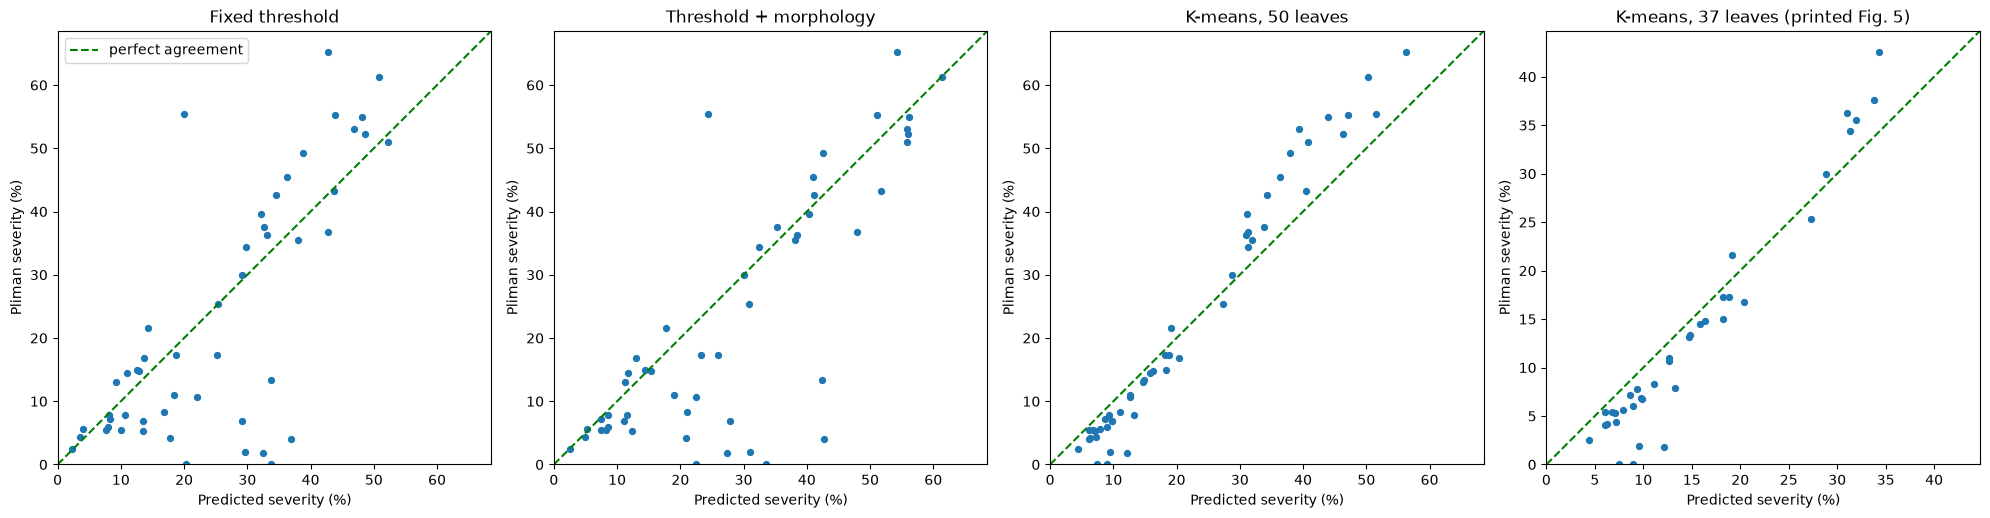

In [3]:
def scatter(ax, pred, reference, title):
    ax.scatter(pred, reference, s=18)
    lim = max(pred.max(), reference.max()) * 1.05
    ax.plot([0, lim], [0, lim], "g--", label="perfect agreement")
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Predicted severity (%)", ylabel="Pliman severity (%)", title=title)
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scatter(axes[0], data["pred_fixed_threshold"], data["pliman_severity"], "Fixed threshold")
scatter(axes[1], data["pred_threshold_morphology"], data["pliman_severity"], "Threshold + morphology")
scatter(axes[2], data["pred_kmeans"], data["pliman_severity"], "K-means, 50 leaves")
scatter(axes[3], printed["pred_kmeans"], printed["pliman_severity"], "K-means, 37 leaves (printed Fig. 5)")
axes[0].legend()
plt.tight_layout(); plt.show()

## Where does K-means differ from Pliman?

The article leaves out, in its last analysis, the leaves on which Pliman had marked healthy tissue as lesion.
Here: how big is the difference by severity range, and what do the left-out leaves look like?

In [4]:
data["difference"] = data["pred_kmeans"] - data["pliman_severity"]

low = data[data["pliman_severity"] <= 10]
high = data[data["pliman_severity"] > 25]
print(f"{len(low)} leaves with Pliman <= 10 %: K-means minus Pliman = {low['difference'].mean():+.1f} points on average")
print(f"{len(high)} leaves with Pliman > 25 %: K-means minus Pliman = {high['difference'].mean():+.1f} points on average")

left_out = data[~data["in_printed_fig5"]]
print(f"\n{len(left_out)} leaves are not in the printed Figure 5. Pliman severity of those leaves: "
      f"{left_out['pliman_severity'].min()} to {left_out['pliman_severity'].max()} %; "
      f"K-means is below Pliman in {(left_out['difference'] < 0).sum()} of them.")
print(f"Highest Pliman severity among the {len(printed)} leaves that are kept: {printed['pliman_severity'].max()} %")

19 leaves with Pliman <= 10 %: K-means minus Pliman = +3.6 points on average
20 leaves with Pliman > 25 %: K-means minus Pliman = -6.7 points on average

13 leaves are not in the printed Figure 5. Pliman severity of those leaves: 36.7 to 65.3 %; K-means is below Pliman in 13 of them.
Highest Pliman severity among the 37 leaves that are kept: 42.6 %


Reading: the 37 leaves that are left cover only low and moderate severities. From these data I cannot tell whether Pliman
was wrong on the 13 left-out leaves, or whether K-means underestimates severe leaves. The article leaves it as a
hypothesis.